# CA6001 Citi Bike Hourly Station Demand Forecasting

This end-to-end notebook implements constrained source-data acquisition, data-quality checks, task-specific panel construction, exploratory visualisation, leakage-safe lag engineering, chronological evaluation, and XGBoost modelling.

**Forecasting task:** predict the number of trip starts (`pickup_count`) for each selected station in the next hour.

**Scope:** January and February 2024, with the 50 stations having the largest number of valid January pickups. Citi Bike is the only behavioural dataset; a deterministic New York holiday calendar is added as calendar metadata.

## 1. Setup and reproducibility

The project uses Python 3.11 and a `uv`-managed environment. Raw CSV files are read directly from ZIP archives in chunks, avoiding large extracted intermediates. All generated datasets are replaced on rerun rather than appended.

In [1]:
from __future__ import annotations

from collections import Counter
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

import folium
import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from branca.colormap import LinearColormap
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURE_DIR = ROOT / "reports" / "figures"
for directory in (RAW_DIR, PROCESSED_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

TOP_N_STATIONS = 50
CHUNK_SIZE = 250_000

SOURCES = {
    "202401": {
        "url": "https://s3.amazonaws.com/tripdata/202401-citibike-tripdata.zip",
        "expected_bytes": 369_035_302,
    },
    "202402": {
        "url": "https://s3.amazonaws.com/tripdata/202402-citibike-tripdata.zip",
        "expected_bytes": 414_712_349,
    },
}

print(f"Project root: {ROOT}")
print(f"Planned raw download: {sum(x['expected_bytes'] for x in SOURCES.values()) / 1e6:.1f} MB")

Project root: /home/gushucheng/CA6001
Planned raw download: 783.7 MB


## 2. Acquire the constrained source data

The download is idempotent. A file with the expected byte size is reused. A new download is first written to a temporary path and then atomically renamed, so an interrupted run does not look complete.

In [2]:
def download_archive(month: str, metadata: dict[str, object]) -> Path:
    destination = RAW_DIR / f"{month}-citibike-tripdata.zip"
    expected_bytes = int(metadata["expected_bytes"])
    if destination.exists() and destination.stat().st_size == expected_bytes:
        print(f"Using existing {destination.name} ({expected_bytes / 1e6:.1f} MB).")
        return destination

    temporary = destination.with_suffix(".zip.part")
    if temporary.exists():
        temporary.unlink()
    print(f"Downloading {destination.name} ...")
    urlretrieve(str(metadata["url"]), temporary)
    actual_bytes = temporary.stat().st_size
    if actual_bytes != expected_bytes:
        raise RuntimeError(
            f"Unexpected size for {destination.name}: {actual_bytes:,} bytes; "
            f"expected {expected_bytes:,} bytes."
        )
    temporary.replace(destination)
    return destination


archives = {month: download_archive(month, metadata) for month, metadata in SOURCES.items()}
archives

Using existing 202401-citibike-tripdata.zip (369.0 MB).
Using existing 202402-citibike-tripdata.zip (414.7 MB).


{'202401': PosixPath('/home/gushucheng/CA6001/data/raw/202401-citibike-tripdata.zip'),
 '202402': PosixPath('/home/gushucheng/CA6001/data/raw/202402-citibike-tripdata.zip')}

In [3]:
archive_inventory = []
for month, archive_path in archives.items():
    with ZipFile(archive_path) as archive:
        corrupt_member = archive.testzip()
        if corrupt_member is not None:
            raise RuntimeError(f"Corrupt ZIP member: {corrupt_member}")
        csv_members = sorted(name for name in archive.namelist() if name.lower().endswith(".csv"))
        archive_inventory.append(
            {
                "month": month,
                "archive_mb": archive_path.stat().st_size / 1e6,
                "csv_files": len(csv_members),
                "csv_names": ", ".join(csv_members),
            }
        )

archive_inventory = pd.DataFrame(archive_inventory)
display(archive_inventory)

,month,archive_mb,csv_files,csv_names
0,202401,369.035302,2,"202401-citibike-tripdata_1.csv, 202401-citibik..."
1,202402,414.712349,3,"202402-citibike-tripdata_1.csv, 202402-citibik..."


## 3. Data definition and quality rules

Only columns required for pickup-demand construction and quality control are read. End-station fields are not required because the target is trip starts. The quality funnel is sequential; each row is counted at the first stage at which it fails.

A valid candidate trip has required identifiers, a start time inside the source month, a valid positive duration no longer than 24 hours, and valid start coordinates. The official source already removes trips shorter than 60 seconds, but duration is checked again to make the transformation robust.

In [4]:
USE_COLUMNS = [
    "ride_id",
    "rideable_type",
    "started_at",
    "ended_at",
    "start_station_name",
    "start_station_id",
    "start_lat",
    "start_lng",
    "member_casual",
]

STRING_COLUMNS = {
    "ride_id": "string",
    "rideable_type": "string",
    "started_at": "string",
    "ended_at": "string",
    "start_station_name": "string",
    "start_station_id": "string",
    "member_casual": "string",
}


def iter_archive_chunks(month: str, archive_path: Path):
    with ZipFile(archive_path) as archive:
        members = sorted(name for name in archive.namelist() if name.lower().endswith(".csv"))
        if not members:
            raise RuntimeError(f"No CSV files found in {archive_path.name}.")
        for member in members:
            with archive.open(member) as csv_file:
                for chunk in pd.read_csv(
                    csv_file,
                    usecols=USE_COLUMNS,
                    dtype=STRING_COLUMNS,
                    chunksize=CHUNK_SIZE,
                    low_memory=False,
                ):
                    chunk["source_month"] = month
                    yield chunk


def clean_chunk(chunk: pd.DataFrame, month: str) -> tuple[pd.DataFrame, dict[str, int]]:
    counts: dict[str, int] = {"raw_rows": len(chunk)}
    required = ["ride_id", "start_station_id", "start_station_name", "started_at", "ended_at"]

    current = chunk.dropna(subset=required).copy()
    counts["after_required_fields"] = len(current)

    current["started_at"] = pd.to_datetime(current["started_at"], errors="coerce")
    current["ended_at"] = pd.to_datetime(current["ended_at"], errors="coerce")
    current = current.dropna(subset=["started_at", "ended_at"])
    counts["after_parseable_timestamps"] = len(current)

    month_start = pd.Timestamp(f"{month[:4]}-{month[4:]}-01")
    month_end = month_start + pd.offsets.MonthBegin(1)
    current = current[current["started_at"].between(month_start, month_end, inclusive="left")]
    counts["after_source_month_check"] = len(current)

    current["duration_minutes"] = (current["ended_at"] - current["started_at"]).dt.total_seconds() / 60
    current = current[current["duration_minutes"].between(1, 24 * 60, inclusive="both")]
    counts["after_duration_check"] = len(current)

    current["start_lat"] = pd.to_numeric(current["start_lat"], errors="coerce")
    current["start_lng"] = pd.to_numeric(current["start_lng"], errors="coerce")
    coordinate_mask = current["start_lat"].between(-90, 90) & current["start_lng"].between(-180, 180)
    current = current[coordinate_mask]
    counts["valid_before_deduplication"] = len(current)
    return current, counts


def add_counts(target: Counter, values: dict[str, int]) -> None:
    for key, value in values.items():
        target[key] += value

## 4. First pass: quality audit and station selection

The first pass counts valid pickups by station without retaining all trips in memory. The top-50 restriction is determined from January only, which is the planned training period. This keeps the station population fixed through time without allowing February validation or test outcomes to influence station selection.

In [5]:
quality_totals: Counter = Counter()
station_pickups: Counter = Counter()

for month, archive_path in archives.items():
    print(f"Auditing {month} ...")
    for raw_chunk in iter_archive_chunks(month, archive_path):
        valid_chunk, chunk_counts = clean_chunk(raw_chunk, month)
        add_counts(quality_totals, chunk_counts)
        if month == "202401":
            station_pickups.update(valid_chunk["start_station_id"].value_counts().to_dict())

quality_order = [
    "raw_rows",
    "after_required_fields",
    "after_parseable_timestamps",
    "after_source_month_check",
    "after_duration_check",
    "valid_before_deduplication",
]
audit = pd.DataFrame(
    {
        "stage": quality_order,
        "rows": [quality_totals[stage] for stage in quality_order],
    }
)
audit["retained_pct_of_raw"] = 100 * audit["rows"] / audit.loc[0, "rows"]
audit.to_csv(PROCESSED_DIR / "quality_audit.csv", index=False)
display(audit)

top_station_ids = [station_id for station_id, _ in station_pickups.most_common(TOP_N_STATIONS)]
print(f"Unique valid start stations: {len(station_pickups):,}")
print(f"Selected stations: {len(top_station_ids):,}")

Auditing 202401 ...


Auditing 202402 ...


,stage,rows,retained_pct_of_raw
0,raw_rows,4009586,100.000000
1,after_required_fields,4006560,99.924531
2,after_parseable_timestamps,4006560,99.924531
3,after_source_month_check,4005919,99.908544
4,after_duration_check,4004717,99.878566
5,valid_before_deduplication,4004717,99.878566


Unique valid start stations: 2,223
Selected stations: 50


## 5. Second pass: construct the filtered trip table

The second pass retains only the selected stations. Duplicate ride IDs are then removed across all files and months. This trip-level table supports traceability and additional EDA; the smaller station-hour panel is the model-ready unit.

In [6]:
filtered_chunks = []
for month, archive_path in archives.items():
    print(f"Filtering {month} ...")
    for raw_chunk in iter_archive_chunks(month, archive_path):
        valid_chunk, _ = clean_chunk(raw_chunk, month)
        selected = valid_chunk[valid_chunk["start_station_id"].isin(top_station_ids)].copy()
        if not selected.empty:
            filtered_chunks.append(selected)

trips = pd.concat(filtered_chunks, ignore_index=True)
duplicate_ride_ids = int(trips.duplicated(subset="ride_id", keep="first").sum())
trips = trips.drop_duplicates(subset="ride_id", keep="first").sort_values("started_at").reset_index(drop=True)
trips["rideable_type"] = trips["rideable_type"].astype("category")
trips["member_casual"] = trips["member_casual"].astype("category")
trips["source_month"] = trips["source_month"].astype("category")
trips.to_parquet(PROCESSED_DIR / "filtered_trips.parquet", index=False)

print(f"Filtered trips: {len(trips):,}")
print(f"Duplicate ride IDs removed: {duplicate_ride_ids:,}")
display(trips.head())

Filtering 202401 ...


Filtering 202402 ...


Filtered trips: 503,407
Duplicate ride IDs removed: 0


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,start_lat,start_lng,member_casual,source_month,duration_minutes
0,7EE460CF0D2AF770,electric_bike,2024-01-01 00:02:14.174,2024-01-01 00:08:37.734,Broadway & E 14 St,5905.12,40.734546,-73.990741,member,202401,6.392667
1,368821B59A484F93,classic_bike,2024-01-01 00:02:16.760,2024-01-01 00:21:42.089,W 43 St & 10 Ave,6756.01,40.760094,-73.994618,casual,202401,19.422150
2,93C1E1A9BA68C92A,electric_bike,2024-01-01 00:03:01.223,2024-01-01 00:08:12.594,8 Ave & W 16 St,6072.11,40.740983,-74.001702,member,202401,5.189517
3,AEC469A98C9EB5C5,electric_bike,2024-01-01 00:03:02.811,2024-01-01 00:10:47.358,Broadway & E 14 St,5905.12,40.734546,-73.990741,casual,202401,7.742450
4,FBB0F4957540523B,electric_bike,2024-01-01 00:03:48.554,2024-01-01 00:16:15.347,E 85 St & 3 Ave,7212.05,40.778012,-73.954071,member,202401,12.446550


## 6. Define and build the model-ready station-hour panel

A row represents one station in one clock hour. The target `pickup_count` is the count of retained trips starting in that station-hour. A complete Cartesian product of 50 stations and all 1,440 hours in the study period is created, so genuine zero-demand hours are not silently omitted. Core calendar features are derived from trip timestamps; the holiday flag comes from a reproducible US/New York calendar rather than another behavioural dataset.

In [7]:
def stable_mode(series: pd.Series) -> str:
    modes = series.dropna().mode()
    return str(modes.iloc[0]) if not modes.empty else "Unknown"


station_metadata = (
    trips.groupby("start_station_id", observed=True)
    .agg(
        station_name=("start_station_name", stable_mode),
        latitude=("start_lat", "median"),
        longitude=("start_lng", "median"),
        total_pickups=("ride_id", "size"),
    )
    .sort_values("total_pickups", ascending=False)
)
station_metadata.to_parquet(PROCESSED_DIR / "station_metadata.parquet")

trip_hours = trips.assign(timestamp=trips["started_at"].dt.floor("h"))
observed_demand = trip_hours.groupby(["start_station_id", "timestamp"], observed=True).size().rename("pickup_count")

all_hours = pd.date_range("2024-01-01 00:00:00", "2024-03-01 00:00:00", freq="h", inclusive="left")
complete_index = pd.MultiIndex.from_product(
    [top_station_ids, all_hours], names=["station_id", "timestamp"]
)
station_hour = observed_demand.reindex(complete_index, fill_value=0).reset_index()
station_hour["pickup_count"] = station_hour["pickup_count"].astype("int32")
station_hour["hour_of_day"] = station_hour["timestamp"].dt.hour.astype("int8")
station_hour["day_of_week"] = station_hour["timestamp"].dt.dayofweek.astype("int8")
station_hour["is_weekend"] = station_hour["day_of_week"].isin([5, 6]).astype("int8")
station_hour["month"] = station_hour["timestamp"].dt.month.astype("int8")
ny_holidays = holidays.US(years=[2024], subdiv="NY")
station_hour["holiday_name"] = station_hour["timestamp"].dt.date.map(ny_holidays.get)
station_hour["is_holiday"] = station_hour["holiday_name"].notna().astype("int8")
station_hour["holiday_name"] = station_hour["holiday_name"].fillna("None").astype("category")
station_hour = station_hour.merge(
    station_metadata.reset_index().rename(columns={"start_station_id": "station_id"}),
    on="station_id",
    how="left",
    validate="many_to_one",
)
station_hour.to_parquet(PROCESSED_DIR / "station_hour_demand.parquet", index=False)
display(station_hour.head())

,station_id,timestamp,pickup_count,hour_of_day,day_of_week,is_weekend,month,holiday_name,is_holiday,station_name,latitude,longitude,total_pickups
0,6140.05,2024-01-01 00:00:00,2,0,0,0,1,New Year's Day,1,W 21 St & 6 Ave,40.74174,-73.994156,17893
1,6140.05,2024-01-01 01:00:00,2,1,0,0,1,New Year's Day,1,W 21 St & 6 Ave,40.74174,-73.994156,17893
2,6140.05,2024-01-01 02:00:00,6,2,0,0,1,New Year's Day,1,W 21 St & 6 Ave,40.74174,-73.994156,17893
3,6140.05,2024-01-01 03:00:00,2,3,0,0,1,New Year's Day,1,W 21 St & 6 Ave,40.74174,-73.994156,17893
4,6140.05,2024-01-01 04:00:00,0,4,0,0,1,New Year's Day,1,W 21 St & 6 Ave,40.74174,-73.994156,17893


### Feature-use decision

`latitude`, `longitude`, `station_name`, and `total_pickups` are carried as descriptive metadata, not default predictors. For this fixed set of 50 stations, categorical `station_id` represents station-specific effects more directly. Using both a one-hot station ID and raw coordinates is largely redundant, while `total_pickups` is an aggregate with leakage risk and must be excluded.

Coordinates are useful for the map below and for an optional spatial-generalisation experiment. If coordinates are later used in a regularised linear model, scale them using parameters fitted on the training set only; tree models do not require coordinate scaling. The binary `is_holiday` field is suitable as a predictor. `holiday_name` is primarily explanatory because each named holiday is rare in this short study window.

In [8]:
expected_rows = TOP_N_STATIONS * len(all_hours)
assert len(station_hour) == expected_rows
assert not station_hour[["station_id", "timestamp"]].duplicated().any()
assert not station_hour.isna().any().any()
assert station_hour["pickup_count"].ge(0).all()
assert station_hour["timestamp"].min() == pd.Timestamp("2024-01-01 00:00:00")
assert station_hour["timestamp"].max() == pd.Timestamp("2024-02-29 23:00:00")

summary = pd.Series(
    {
        "trip_rows": len(trips),
        "stations": station_hour["station_id"].nunique(),
        "hours": station_hour["timestamp"].nunique(),
        "panel_rows": len(station_hour),
        "zero_demand_share": station_hour["pickup_count"].eq(0).mean(),
        "mean_pickups_per_station_hour": station_hour["pickup_count"].mean(),
        "maximum_pickups_in_one_station_hour": station_hour["pickup_count"].max(),
    },
    name="value",
)
display(summary.to_frame())

,value
trip_rows,503407.000000
stations,50.000000
hours,1440.000000
panel_rows,72000.000000
zero_demand_share,0.179097
mean_pickups_per_station_hour,6.991764
maximum_pickups_in_one_station_hour,73.000000


## 7. Preliminary visualisation

The following plots inspect temporal demand, the weekly-hourly pattern, differences between stations, and the spatial distribution of the selected stations. The interactive map uses OpenStreetMap-based tiles through Folium; the marker data still come only from Citi Bike. These plots are descriptive and do not establish causal relationships.

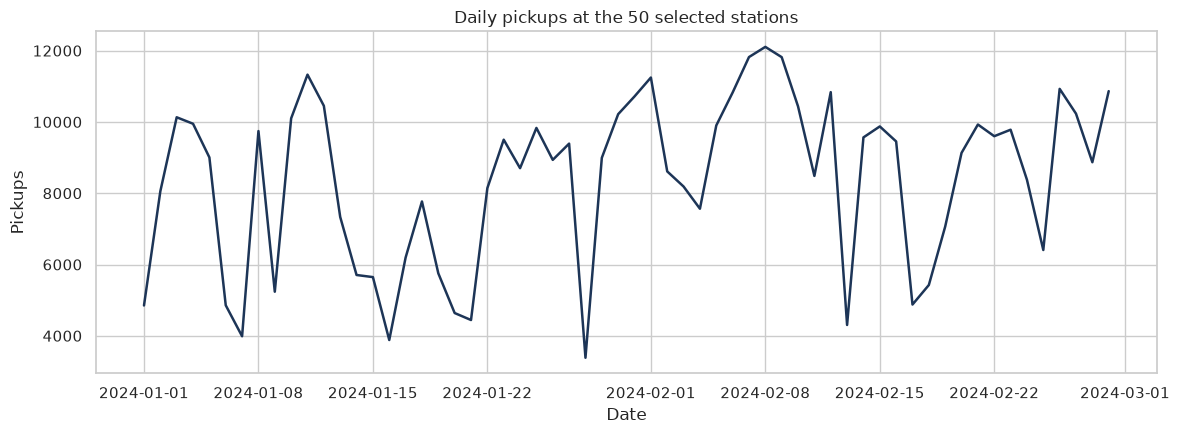

In [9]:
daily_demand = station_hour.groupby(station_hour["timestamp"].dt.date)["pickup_count"].sum()
fig, ax = plt.subplots(figsize=(12, 4.5))
daily_demand.plot(ax=ax, color="#1D3557", linewidth=1.8)
ax.set(title="Daily pickups at the 50 selected stations", xlabel="Date", ylabel="Pickups")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02_daily_pickups.png", dpi=160, bbox_inches="tight")
plt.show()

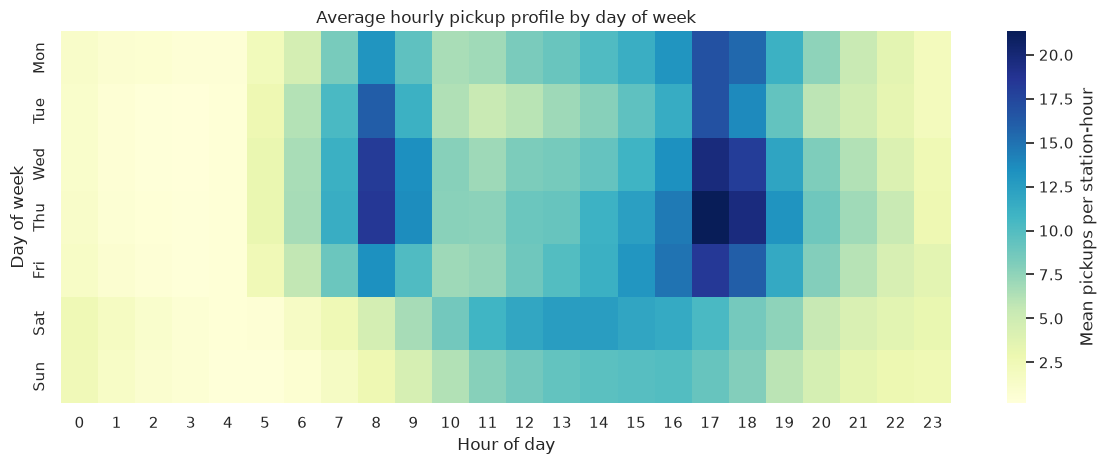

In [10]:
weekday_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
hourly_profile = station_hour.groupby(["day_of_week", "hour_of_day"])["pickup_count"].mean().unstack()
hourly_profile.index = weekday_labels
fig, ax = plt.subplots(figsize=(12, 4.8))
sns.heatmap(hourly_profile, cmap="YlGnBu", ax=ax, cbar_kws={"label": "Mean pickups per station-hour"})
ax.set(title="Average hourly pickup profile by day of week", xlabel="Hour of day", ylabel="Day of week")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "03_weekday_hour_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

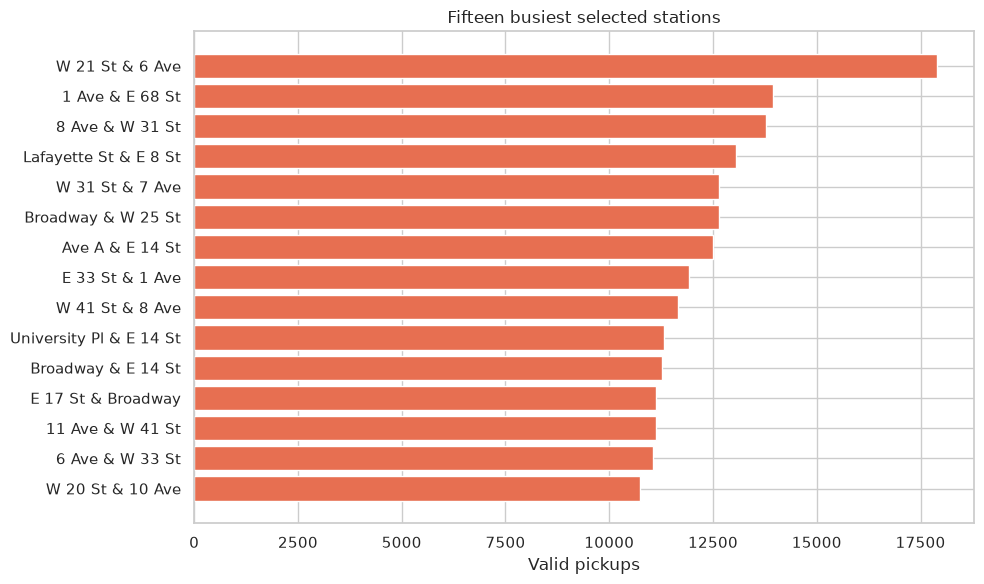

In [11]:
top_15 = station_metadata.head(15).sort_values("total_pickups")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_15["station_name"], top_15["total_pickups"], color="#E76F51")
ax.set(title="Fifteen busiest selected stations", xlabel="Valid pickups", ylabel="")
ax.ticklabel_format(style="plain", axis="x")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "04_top_stations.png", dpi=160, bbox_inches="tight")
plt.show()

In [12]:
map_data = station_metadata.reset_index()
activity_min = float(map_data["total_pickups"].min())
activity_max = float(map_data["total_pickups"].max())
colour_scale = LinearColormap(
    colors=["#FFF3B0", "#F4A261", "#E76F51", "#9B2226"],
    vmin=activity_min,
    vmax=activity_max,
    caption="Valid pickups, January-February 2024",
)
activity_map = folium.Map(
    location=[map_data["latitude"].median(), map_data["longitude"].median()],
    zoom_start=12,
    tiles="CartoDB positron",
    control_scale=True,
)
for row in map_data.itertuples(index=False):
    relative_activity = (row.total_pickups - activity_min) / (activity_max - activity_min)
    folium.CircleMarker(
        location=[row.latitude, row.longitude],
        radius=5 + 10 * np.sqrt(relative_activity),
        color=colour_scale(row.total_pickups),
        fill=True,
        fill_color=colour_scale(row.total_pickups),
        fill_opacity=0.75,
        weight=1,
        tooltip=f"{row.station_name}: {row.total_pickups:,} pickups",
        popup=folium.Popup(
            f"<b>{row.station_name}</b><br>Station ID: {row.start_station_id}<br>"
            f"Valid pickups: {row.total_pickups:,}",
            max_width=300,
        ),
    ).add_to(activity_map)
colour_scale.add_to(activity_map)
map_path = FIGURE_DIR / "05_station_activity_map.html"
activity_map.save(str(map_path))
activity_map

/home/gushucheng/CA6001/.venv/lib/python3.11/site-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


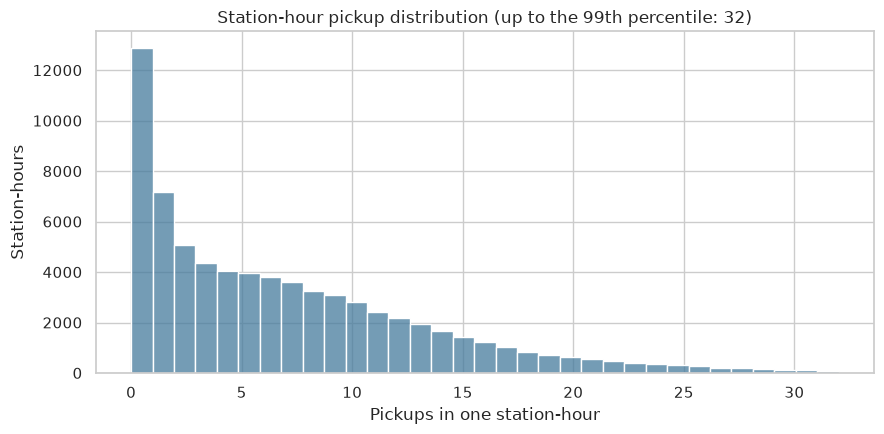

In [13]:
upper_limit = int(station_hour["pickup_count"].quantile(0.99))
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(
    station_hour.loc[station_hour["pickup_count"] <= upper_limit, "pickup_count"],
    bins=min(40, upper_limit + 1),
    color="#457B9D",
    ax=ax,
)
ax.set(
    title=f"Station-hour pickup distribution (up to the 99th percentile: {upper_limit})",
    xlabel="Pickups in one station-hour",
    ylabel="Station-hours",
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "06_pickup_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. EDA summary and modelling transition

The processed table is ready for chronological modelling. The following sections add lagged and rolling demand features using only earlier observations, then compare a weekly seasonal-naive baseline with XGBoost. The first seven days initialise long lags; training uses 8 January–7 February, validation uses 8–14 February, and testing uses 15–29 February. Random train/test splitting must not be used.

Important limitations are the two-month winter scope, selection bias toward high-volume stations, the small number of holidays, and the absence of weather, station-capacity, and live inventory information. Consequently, the target is observed pickup demand among the selected stations, not the probability that a station becomes empty.

# Part II – Forecasting Model and Evaluation

The following sections extend the prepared station-hour panel with short- and long-term lag features, define a chronological train/validation/test design, train an XGBoost count regressor, and compare it with a weekly seasonal-naive baseline.

**Forecasting interpretation:** rolling one-hour-ahead prediction. Demand through hour $t-1$ is assumed to be observed when predicting hour $t$. This is not a recursive multi-hour forecast.

## 9. Modelling setup and input validation

The data-preparation sections above must be executed first. The model uses the balanced station-hour panel and deliberately excludes descriptive metadata such as coordinates and `total_pickups`.

In [14]:
from __future__ import annotations

from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURE_DIR = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "models"
for directory in (PROCESSED_DIR, FIGURE_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

INPUT_PATH = PROCESSED_DIR / "station_hour_demand.parquet"
if not INPUT_PATH.exists():
    raise FileNotFoundError("Run the data-preparation sections above before modelling.")

panel = pd.read_parquet(INPUT_PATH).sort_values(["station_id", "timestamp"]).reset_index(drop=True)
panel["station_id"] = panel["station_id"].astype("string")

print(f"pandas: {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"xgboost: {xgboost.__version__}")
print(f"Input rows: {len(panel):,}; stations: {panel['station_id'].nunique()}; hours: {panel['timestamp'].nunique():,}")

pandas: 2.3.3
scikit-learn: 1.9.1
xgboost: 3.2.0
Input rows: 72,000; stations: 50; hours: 1,440


In [15]:
expected_columns = {
    "station_id", "timestamp", "pickup_count", "hour_of_day",
    "day_of_week", "is_weekend", "is_holiday",
}
missing_columns = expected_columns.difference(panel.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

assert not panel[["station_id", "timestamp"]].duplicated().any()
assert panel["pickup_count"].ge(0).all()
assert panel.groupby("station_id")["timestamp"].diff().dropna().eq(pd.Timedelta(hours=1)).all()
display(panel.head())

,station_id,timestamp,pickup_count,hour_of_day,day_of_week,is_weekend,month,holiday_name,is_holiday,station_name,latitude,longitude,total_pickups
0,5303.06,2024-01-01 00:00:00,3,0,0,0,1,New Year's Day,1,Clinton St & Grand St,40.715595,-73.98703,10709
1,5303.06,2024-01-01 01:00:00,2,1,0,0,1,New Year's Day,1,Clinton St & Grand St,40.715595,-73.98703,10709
2,5303.06,2024-01-01 02:00:00,0,2,0,0,1,New Year's Day,1,Clinton St & Grand St,40.715595,-73.98703,10709
3,5303.06,2024-01-01 03:00:00,3,3,0,0,1,New Year's Day,1,Clinton St & Grand St,40.715595,-73.98703,10709
4,5303.06,2024-01-01 04:00:00,1,4,0,0,1,New Year's Day,1,Clinton St & Grand St,40.715595,-73.98703,10709


## 10. Leakage-safe lag and rolling features

Short lags (1, 2, 3, and 6 hours) capture recent station conditions. Long lags (24, 48, and 168 hours) capture daily and weekly repetition. Rolling means and standard deviations are shifted by one hour before aggregation, ensuring that the current target is never included in its own predictors.

The first 168 hours per station become history-only rows and are excluded from modelling after feature construction.

In [16]:
SHORT_LAGS = [1, 2, 3, 6]
LONG_LAGS = [24, 48, 168]
ROLLING_WINDOWS = [3, 6, 24, 168]

modeling = panel.copy()
station_target = modeling.groupby("station_id", sort=False)["pickup_count"]

for lag in SHORT_LAGS + LONG_LAGS:
    modeling[f"lag_{lag}h"] = station_target.shift(lag)

for window in ROLLING_WINDOWS:
    modeling[f"rolling_mean_{window}h"] = station_target.transform(
        lambda values: values.shift(1).rolling(window=window, min_periods=window).mean()
    )
    modeling[f"rolling_std_{window}h"] = station_target.transform(
        lambda values: values.shift(1).rolling(window=window, min_periods=window).std(ddof=0)
    )

modeling["hour_sin"] = np.sin(2 * np.pi * modeling["hour_of_day"] / 24)
modeling["hour_cos"] = np.cos(2 * np.pi * modeling["hour_of_day"] / 24)
modeling["dow_sin"] = np.sin(2 * np.pi * modeling["day_of_week"] / 7)
modeling["dow_cos"] = np.cos(2 * np.pi * modeling["day_of_week"] / 7)

lag_columns = [f"lag_{lag}h" for lag in SHORT_LAGS + LONG_LAGS]
rolling_columns = [
    feature
    for window in ROLLING_WINDOWS
    for feature in (f"rolling_mean_{window}h", f"rolling_std_{window}h")
]
calendar_columns = ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "is_weekend", "is_holiday"]
numeric_features = calendar_columns + lag_columns + rolling_columns

modeling = modeling.dropna(subset=lag_columns + rolling_columns).reset_index(drop=True)
modeling.to_parquet(PROCESSED_DIR / "modeling_dataset.parquet", index=False)

print(f"Model-ready rows: {len(modeling):,}")
print(f"Numeric predictors before station encoding: {len(numeric_features)}")
display(modeling[["station_id", "timestamp", "pickup_count"] + lag_columns + rolling_columns].head())

Model-ready rows: 63,600
Numeric predictors before station encoding: 21


,station_id,timestamp,pickup_count,lag_1h,lag_2h,lag_3h,lag_6h,lag_24h,lag_48h,lag_168h,rolling_mean_3h,rolling_std_3h,rolling_mean_6h,rolling_std_6h,rolling_mean_24h,rolling_std_24h,rolling_mean_168h,rolling_std_168h
0,5303.06,2024-01-08 00:00:00,1,2.0,5.0,4.0,8.0,0.0,0.0,3.0,3.666667,1.247219,6.000000,2.516611,4.708333,4.513675,6.797619,6.486763
1,5303.06,2024-01-08 01:00:00,0,1.0,2.0,5.0,8.0,0.0,0.0,2.0,2.666667,1.699673,4.833333,2.910708,4.750000,4.474465,6.785714,6.495551
2,5303.06,2024-01-08 02:00:00,0,0.0,1.0,2.0,9.0,0.0,0.0,0.0,1.000000,0.816497,3.500000,2.986079,4.750000,4.474465,6.773810,6.506135
3,5303.06,2024-01-08 03:00:00,0,0.0,0.0,1.0,4.0,0.0,0.0,3.0,0.333333,0.471405,2.000000,1.914854,4.750000,4.474465,6.773810,6.506135
4,5303.06,2024-01-08 04:00:00,0,0.0,0.0,0.0,5.0,0.0,0.0,1.0,0.000000,0.000000,1.333333,1.795055,4.750000,4.474465,6.755952,6.520569


## 11. Chronological data split

- **History only:** 1–7 January, needed to initialise the 168-hour features.
- **Training:** 8 January–7 February.
- **Validation:** 8–14 February, used for early stopping.
- **Test:** 15–29 February, evaluated once after model selection.

Random splitting would allow observations from the future to inform training and is therefore inappropriate. Lag features in validation and test use actual earlier demand, consistent with the one-hour-ahead operational setting.

In [17]:
TRAIN_START = pd.Timestamp("2024-01-08 00:00:00")
VALID_START = pd.Timestamp("2024-02-08 00:00:00")
TEST_START = pd.Timestamp("2024-02-15 00:00:00")
TEST_END = pd.Timestamp("2024-03-01 00:00:00")

train = modeling[modeling["timestamp"].between(TRAIN_START, VALID_START, inclusive="left")].copy()
valid = modeling[modeling["timestamp"].between(VALID_START, TEST_START, inclusive="left")].copy()
test = modeling[modeling["timestamp"].between(TEST_START, TEST_END, inclusive="left")].copy()

assert train["timestamp"].max() < valid["timestamp"].min()
assert valid["timestamp"].max() < test["timestamp"].min()
assert train["station_id"].nunique() == valid["station_id"].nunique() == test["station_id"].nunique() == 50

split_summary = pd.DataFrame(
    [
        {"split": name, "start": frame["timestamp"].min(), "end": frame["timestamp"].max(), "rows": len(frame)}
        for name, frame in (("train", train), ("validation", valid), ("test", test))
    ]
)
display(split_summary)

,split,start,end,rows
0,train,2024-01-08,2024-02-07 23:00:00,37200
1,validation,2024-02-08,2024-02-14 23:00:00,8400
2,test,2024-02-15,2024-02-29 23:00:00,18000


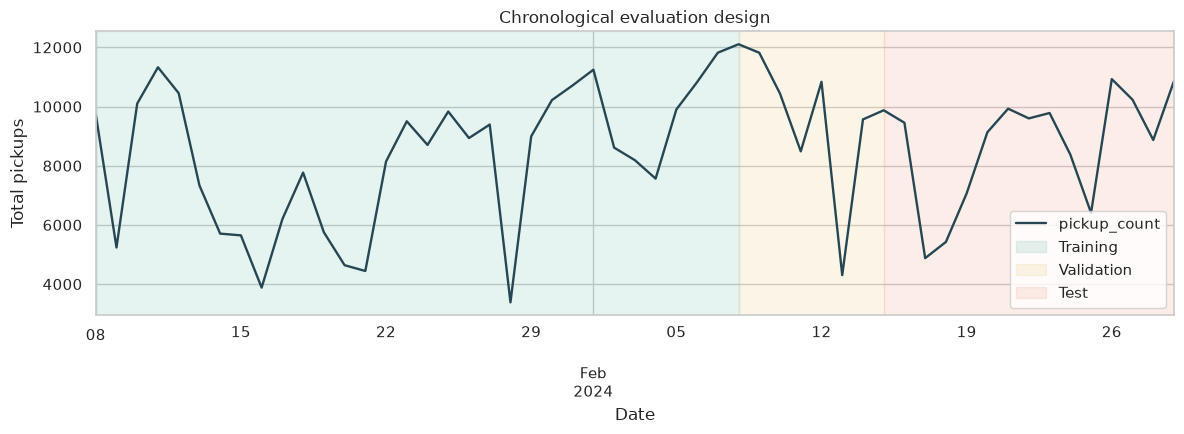

In [18]:
daily_total = modeling.groupby(modeling["timestamp"].dt.floor("D"))["pickup_count"].sum()
fig, ax = plt.subplots(figsize=(12, 4.5))
daily_total.plot(ax=ax, color="#264653", linewidth=1.7)
ax.axvspan(TRAIN_START, VALID_START, alpha=0.12, color="#2A9D8F", label="Training")
ax.axvspan(VALID_START, TEST_START, alpha=0.16, color="#E9C46A", label="Validation")
ax.axvspan(TEST_START, TEST_END, alpha=0.12, color="#E76F51", label="Test")
ax.set(title="Chronological evaluation design", xlabel="Date", ylabel="Total pickups")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "07_data_split.png", dpi=160, bbox_inches="tight")
plt.show()

## 12. Design matrices and baseline

Station ID is one-hot encoded using the 50 categories selected from the January training period. Coordinates and `total_pickups` are excluded. The weekly seasonal-naive baseline predicts the current pickup count using the same station and hour exactly 168 hours earlier.

In [19]:
station_categories = sorted(train["station_id"].unique())


def make_design_matrix(frame: pd.DataFrame) -> pd.DataFrame:
    numeric = frame[numeric_features].reset_index(drop=True).astype("float32")
    station = pd.Categorical(frame["station_id"], categories=station_categories)
    station_dummies = pd.get_dummies(station, prefix="station", dtype="float32")
    return pd.concat([numeric, station_dummies], axis=1)


X_train = make_design_matrix(train)
X_valid = make_design_matrix(valid)
X_test = make_design_matrix(test)
y_train = train["pickup_count"].to_numpy(dtype="float32")
y_valid = valid["pickup_count"].to_numpy(dtype="float32")
y_test = test["pickup_count"].to_numpy(dtype="float32")

assert X_train.columns.equals(X_valid.columns) and X_train.columns.equals(X_test.columns)
assert not X_train.isna().any().any()
print(f"Design matrix: {X_train.shape[1]} predictors")
print(f"Training rows: {len(X_train):,}; validation rows: {len(X_valid):,}; test rows: {len(X_test):,}")

Design matrix: 71 predictors
Training rows: 37,200; validation rows: 8,400; test rows: 18,000


## 13. XGBoost training

A Poisson count objective keeps predictions non-negative and matches the non-negative count target. Histogram tree construction limits computational cost. The validation MAE controls early stopping; the test set is not passed to training. Hyperparameters are intentionally moderate rather than extensively tuned on this small project.

In [20]:
model = XGBRegressor(
    objective="count:poisson",
    eval_metric="mae",
    n_estimators=1_500,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=8,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.05,
    reg_lambda=2.0,
    tree_method="hist",
    early_stopping_rounds=75,
    random_state=42,
    n_jobs=-1,
)
model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_valid, y_valid)],
    verbose=False,
)
model.save_model(MODEL_DIR / "xgboost_hourly_demand.json")
print(f"Best boosting iteration: {model.best_iteration}")
print(f"Best validation MAE: {model.best_score:.4f}")

Best boosting iteration: 410
Best validation MAE: 2.7823


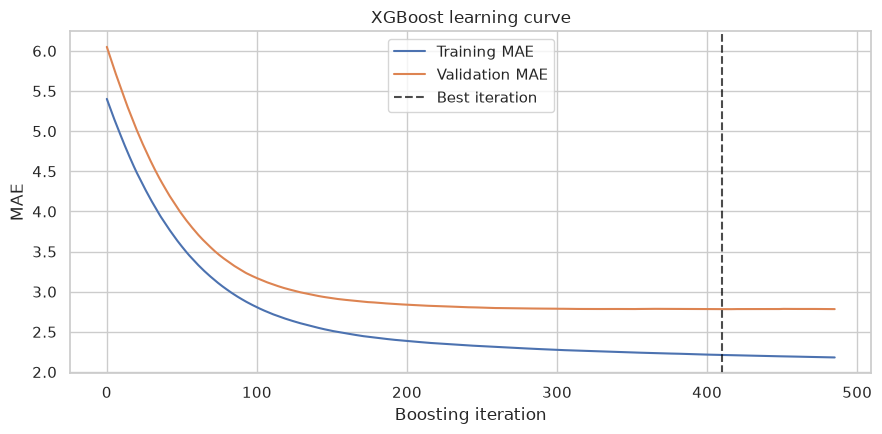

In [21]:
evaluation_history = model.evals_result()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(evaluation_history["validation_0"]["mae"], label="Training MAE", linewidth=1.5)
ax.plot(evaluation_history["validation_1"]["mae"], label="Validation MAE", linewidth=1.5)
ax.axvline(model.best_iteration, color="black", linestyle="--", alpha=0.7, label="Best iteration")
ax.set(title="XGBoost learning curve", xlabel="Boosting iteration", ylabel="MAE")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "08_training_curve.png", dpi=160, bbox_inches="tight")
plt.show()

## 14. Validation and test evaluation

MAE is the primary metric because it is directly interpretable as pickups per station-hour. RMSE gives additional weight to large misses, WAPE normalises aggregate absolute error by aggregate demand, and $R^2$ is reported as a supplementary measure. Continuous predictions are retained rather than rounded.

In [22]:
def regression_metrics(actual: np.ndarray, predicted: np.ndarray) -> dict[str, float]:
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "WAPE_pct": 100 * np.abs(actual - predicted).sum() / np.abs(actual).sum(),
        "R2": r2_score(actual, predicted),
    }


valid_xgb = model.predict(X_valid)
test_xgb = model.predict(X_test)
valid_baseline = valid["lag_168h"].to_numpy(dtype="float32")
test_baseline = test["lag_168h"].to_numpy(dtype="float32")

metric_rows = []
for split_name, actual, baseline_prediction, xgb_prediction in (
    ("validation", y_valid, valid_baseline, valid_xgb),
    ("test", y_test, test_baseline, test_xgb),
):
    for model_name, prediction in (("Weekly seasonal naive", baseline_prediction), ("XGBoost", xgb_prediction)):
        metric_rows.append({"split": split_name, "model": model_name, **regression_metrics(actual, prediction)})

metrics = pd.DataFrame(metric_rows)
metrics.to_csv(PROCESSED_DIR / "model_metrics.csv", index=False)
display(metrics.round(4))

test_predictions = test[["station_id", "station_name", "timestamp", "pickup_count"]].copy()
test_predictions["seasonal_naive_prediction"] = test_baseline
test_predictions["xgboost_prediction"] = test_xgb
test_predictions["xgboost_error"] = test_xgb - y_test
test_predictions.to_parquet(PROCESSED_DIR / "test_predictions.parquet", index=False)

,split,model,MAE,RMSE,WAPE_pct,R2
0,validation,Weekly seasonal naive,3.7448,5.7255,46.564899,0.4918
1,validation,XGBoost,2.7823,4.0952,34.596699,0.7400
2,test,Weekly seasonal naive,3.7396,5.7369,51.455898,0.3827
3,test,XGBoost,2.4830,3.7290,34.166302,0.7392


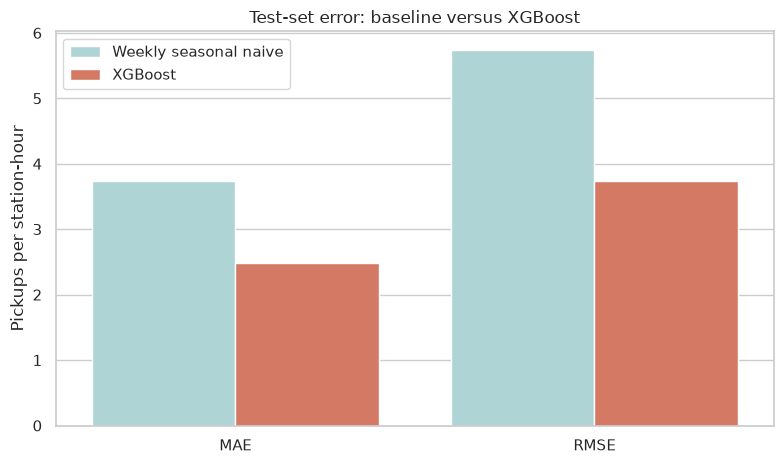

In [23]:
test_metric_plot = metrics[metrics["split"].eq("test")].melt(
    id_vars=["model"], value_vars=["MAE", "RMSE"], var_name="metric", value_name="value"
)
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.barplot(data=test_metric_plot, x="metric", y="value", hue="model", palette=["#A8DADC", "#E76F51"], ax=ax)
ax.set(title="Test-set error: baseline versus XGBoost", xlabel="", ylabel="Pickups per station-hour")
ax.legend(title="")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "09_model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

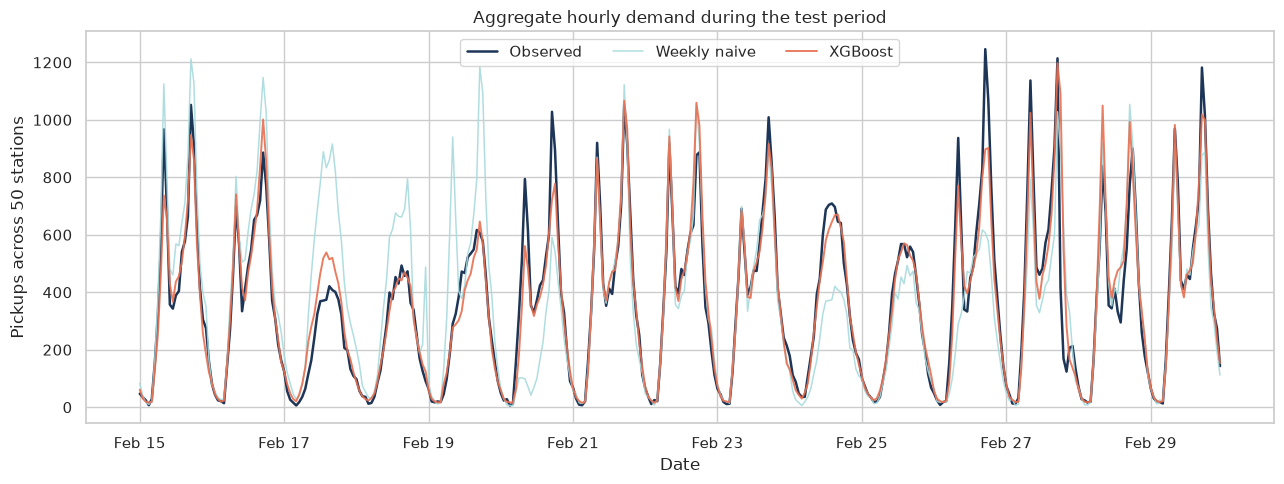

In [24]:
aggregate_test = test_predictions.groupby("timestamp")[["pickup_count", "seasonal_naive_prediction", "xgboost_prediction"]].sum()
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(aggregate_test.index, aggregate_test["pickup_count"], label="Observed", color="#1D3557", linewidth=1.8)
ax.plot(aggregate_test.index, aggregate_test["seasonal_naive_prediction"], label="Weekly naive", color="#A8DADC", linewidth=1.1, alpha=0.9)
ax.plot(aggregate_test.index, aggregate_test["xgboost_prediction"], label="XGBoost", color="#E76F51", linewidth=1.4, alpha=0.9)
ax.set(title="Aggregate hourly demand during the test period", xlabel="Date", ylabel="Pickups across 50 stations")
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(ncol=3)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "10_test_predictions.png", dpi=160, bbox_inches="tight")
plt.show()

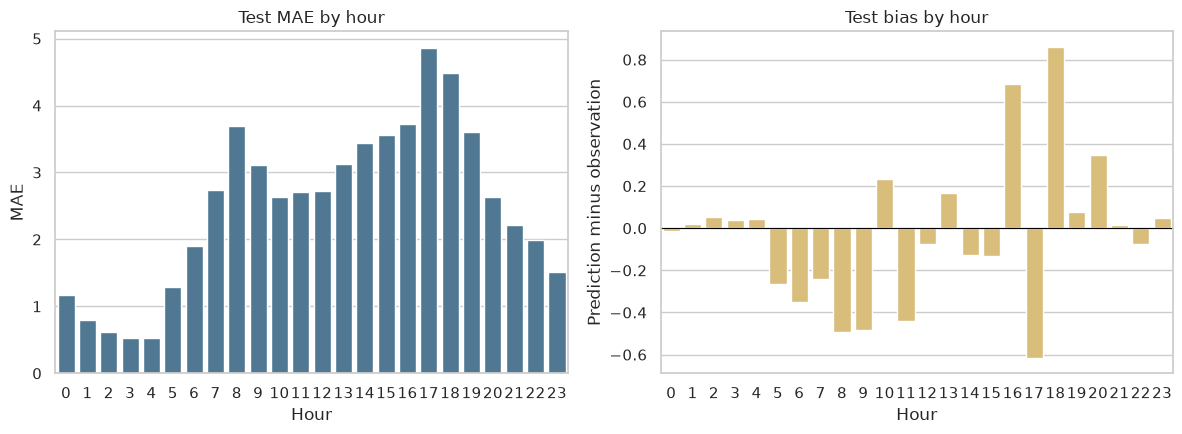

In [25]:
test_predictions["hour_of_day"] = test_predictions["timestamp"].dt.hour
hourly_error = test_predictions.groupby("hour_of_day")["xgboost_error"].agg(
    MAE=lambda values: values.abs().mean(),
    bias="mean",
).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
sns.barplot(data=hourly_error, x="hour_of_day", y="MAE", color="#457B9D", ax=axes[0])
sns.barplot(data=hourly_error, x="hour_of_day", y="bias", color="#E9C46A", ax=axes[1])
axes[0].set(title="Test MAE by hour", xlabel="Hour", ylabel="MAE")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(title="Test bias by hour", xlabel="Hour", ylabel="Prediction minus observation")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "11_error_by_hour.png", dpi=160, bbox_inches="tight")
plt.show()

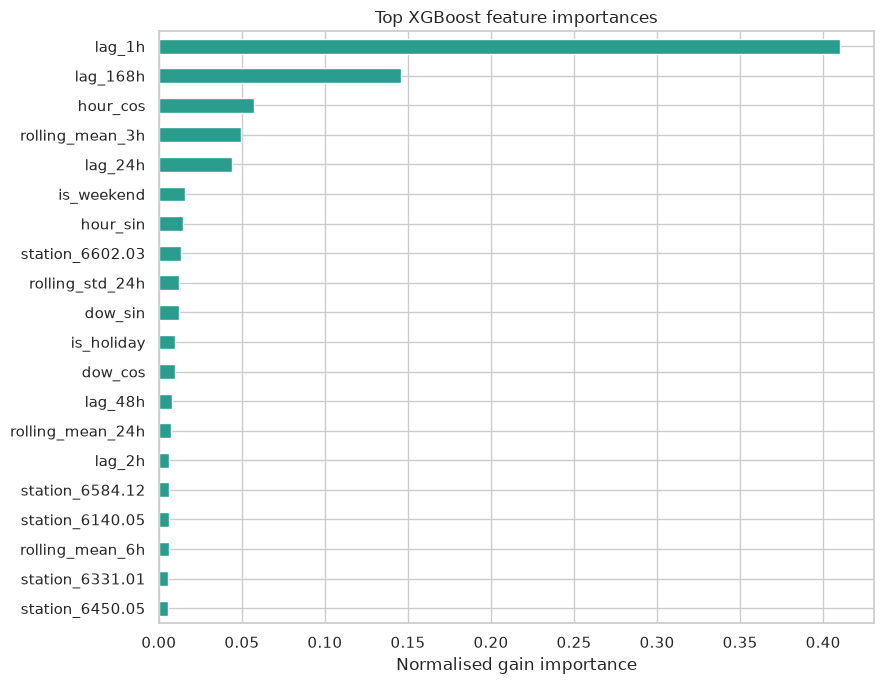

,importance
lag_1h,0.410097
lag_168h,0.145858
hour_cos,0.057034
rolling_mean_3h,0.049558
lag_24h,0.044123
is_weekend,0.015599
hour_sin,0.014318
station_6602.03,0.013373
rolling_std_24h,0.012207
dow_sin,0.012169


In [26]:
feature_importance = (
    pd.Series(model.feature_importances_, index=X_train.columns, name="importance")
    .sort_values(ascending=False)
    .head(20)
    .sort_values()
)
fig, ax = plt.subplots(figsize=(9, 7))
feature_importance.plot.barh(ax=ax, color="#2A9D8F")
ax.set(title="Top XGBoost feature importances", xlabel="Normalised gain importance", ylabel="")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "12_feature_importance.png", dpi=160, bbox_inches="tight")
plt.show()
display(feature_importance.sort_values(ascending=False).to_frame())

## 15. Interpretation boundaries and next experiments

The weekly baseline is the minimum meaningful comparator because it already captures station, weekday, and hour effects. XGBoost should be considered useful only if it improves test MAE/WAPE over this baseline, not merely because its training error is low.

Feature importance describes how the fitted trees used variables; it is not a causal effect. Holiday usefulness should be tested with an explicit ablation model. Additional defensible experiments include removing short lags, removing long lags, comparing a regularised linear model, and reporting station-level errors. The current results apply only to high-volume stations in January–February 2024 and to one-hour-ahead forecasting with observed recent demand.